In [2]:
pip install numpy pandas matplotlib scikit-learn



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error

In [ ]:
dst = pd.read_csv('../datasets/data.csv')


FileNotFoundError: [Errno 2] No such file or directory: '../datasets/data.csv'

In [5]:
dst.head()


,market,country_code,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
0,News,USA,2012,1750000.0,1,0.0,1750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,Advertising,ARG,2007,4912393.0,1,4912393.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,Curated Web,USA,2010,2535000.0,2,0.0,15000.0,0.0,0.0,0.0,...,0.0,2520000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,Analytics,USA,2011,1250000.0,2,500000.0,750000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,Curated Web,USA,2009,50000.0,1,0.0,50000.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [ ]:
print('Shape:',dst.shape)
print('Size :',dst.size)
print('Column Names :',dst.columns.tolist())
print('Number of columns :',len(dst.columns.tolist()))
print('numbers of rows :',dst.shape[0])
print()
print('Datatype of each column :')
print(dst.dtypes)      #datatypes of every column

Shape: (4757, 23)
Size : 109411
Column Names : ['market', 'country_code', 'founded_year', 'funding_total_usd', 'funding_rounds', 'unclassified_funding', 'seed', 'angel', 'equity_crowdfunding', 'convertible_note', 'debt_financing', 'grant', 'private_equity', 'product_crowdfunding', 'round_A', 'round_B', 'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H', 'status']
Number of columns : 23
numbers of rows : 4757

Datatype of each column :
market                      str
country_code                str
founded_year              int64
funding_total_usd       float64
funding_rounds            int64
unclassified_funding    float64
seed                    float64
angel                   float64
equity_crowdfunding     float64
convertible_note        float64
debt_financing          float64
grant                   float64
private_equity          float64
product_crowdfunding    float64
round_A                 float64
round_B                 float64
round_C                 float64
rou

In [7]:
dst.info()

<class 'pandas.DataFrame'>
RangeIndex: 4757 entries, 0 to 4756
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   market                4757 non-null   str    
 1   country_code          4757 non-null   str    
 2   founded_year          4757 non-null   int64  
 3   funding_total_usd     4757 non-null   float64
 4   funding_rounds        4757 non-null   int64  
 5   unclassified_funding  4757 non-null   float64
 6   seed                  4757 non-null   float64
 7   angel                 4757 non-null   float64
 8   equity_crowdfunding   4757 non-null   float64
 9   convertible_note      4757 non-null   float64
 10  debt_financing        4757 non-null   float64
 11  grant                 4757 non-null   float64
 12  private_equity        4757 non-null   float64
 13  product_crowdfunding  4757 non-null   float64
 14  round_A               4757 non-null   float64
 15  round_B               4757 non-n

In [8]:
dst.isnull().sum()

market                  0
country_code            0
founded_year            0
funding_total_usd       0
funding_rounds          0
unclassified_funding    0
seed                    0
angel                   0
equity_crowdfunding     0
convertible_note        0
debt_financing          0
grant                   0
private_equity          0
product_crowdfunding    0
round_A                 0
round_B                 0
round_C                 0
round_D                 0
round_E                 0
round_F                 0
round_G                 0
round_H                 0
status                  0
dtype: int64

In [9]:
print("No. of duplicate rows" , dst.duplicated().sum())

No. of duplicate rows 18


In [10]:
print("Summary", dst.describe())

Summary        founded_year  funding_total_usd  funding_rounds  unclassified_funding  \
count   4757.000000       4.757000e+03     4757.000000          4.757000e+03   
mean    2005.897204       1.834339e+07        1.951860          4.613512e+06   
std        4.090614       9.819188e+07        1.354832          8.278538e+07   
min     1990.000000       1.000000e+03        1.000000          0.000000e+00   
25%     2004.000000       1.000000e+06        1.000000          0.000000e+00   
50%     2007.000000       5.000000e+06        1.000000          0.000000e+00   
75%     2009.000000       1.640000e+07        2.000000          1.507400e+06   
max     2014.000000       5.700000e+09       15.000000          5.620000e+09   

               seed         angel  equity_crowdfunding  convertible_note  \
count  4.757000e+03  4.757000e+03         4.757000e+03      4.757000e+03   
mean   1.934164e+05  8.648298e+04         1.671221e+03      1.022975e+04   
std    7.634434e+05  6.459516e+05         8

In [11]:
dst.describe()

,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,debt_financing,grant,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
count,4757.000000,4.757000e+03,4757.000000,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,...,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4757.0,4757.000000
mean,2005.897204,1.834339e+07,1.951860,4.613512e+06,1.934164e+05,8.648298e+04,1.671221e+03,1.022975e+04,1.553380e+06,3.765643e+04,...,5.675846e+02,2.112195e+06,3.119906e+06,2.370277e+06,1.322005e+06,5.142878e+05,2.097414e+05,2.848434e+04,0.0,0.619718
std,4.090614,9.819188e+07,1.354832,8.278538e+07,7.634434e+05,6.459516e+05,8.700127e+04,2.318734e+05,2.526918e+07,1.503298e+06,...,3.506712e+04,7.067711e+06,9.925746e+06,8.634016e+06,8.849721e+06,5.243109e+06,4.982326e+06,1.188800e+06,0.0,0.485507
min,1990.000000,1.000000e+03,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
25%,2004.000000,1.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
50%,2007.000000,5.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
75%,2009.000000,1.640000e+07,2.000000,1.507400e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
max,2014.000000,5.700000e+09,15.000000,5.620000e+09,2.500000e+07,3.000000e+07,5.500000e+06,1.352014e+07,1.200000e+09,9.980000e+07,...,2.400000e+06,2.250000e+08,3.500000e+08,2.000000e+08,2.500000e+08,2.200000e+08,2.860000e+08,6.300000e+07,0.0,1.000000


In [16]:
dst['status'].value_counts()

status
1    2948
0    1809
Name: count, dtype: int64

In [17]:
dst['status'].value_counts(normalize=True) * 100

status
1    61.971831
0    38.028169
Name: proportion, dtype: float64

In [18]:
dst.duplicated().sum()

np.int64(18)

In [19]:
dst.columns.tolist()

['market',
 'country_code',
 'founded_year',
 'funding_total_usd',
 'funding_rounds',
 'unclassified_funding',
 'seed',
 'angel',
 'equity_crowdfunding',
 'convertible_note',
 'debt_financing',
 'grant',
 'private_equity',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H',
 'status']

In [20]:
dst.select_dtypes(include='number').columns.tolist()

['founded_year',
 'funding_total_usd',
 'funding_rounds',
 'unclassified_funding',
 'seed',
 'angel',
 'equity_crowdfunding',
 'convertible_note',
 'debt_financing',
 'grant',
 'private_equity',
 'product_crowdfunding',
 'round_A',
 'round_B',
 'round_C',
 'round_D',
 'round_E',
 'round_F',
 'round_G',
 'round_H',
 'status']

In [21]:
dst.select_dtypes(include='object').columns.tolist()

/var/folders/00/4mdl762x699f4cdgzb84006h0000gn/T/ipykernel_86533/836994305.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dst.select_dtypes(include='object').columns.tolist()


['market', 'country_code']

In [22]:
for col in dst.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(dst[col].nunique())


market:
377

country_code:
61


/var/folders/00/4mdl762x699f4cdgzb84006h0000gn/T/ipykernel_86533/2045612511.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in dst.select_dtypes(include='object').columns:


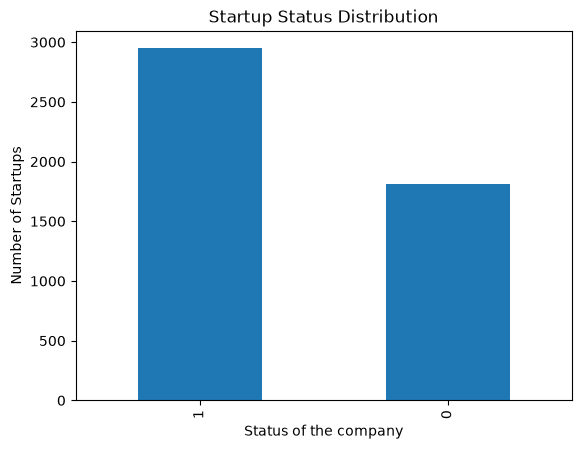

In [24]:
dst['status'].value_counts().plot(kind='bar')
plt.title('Startup Status Distribution')
plt.xlabel('Status of the company')
plt.ylabel('Number of Startups')
plt.show()

In [26]:
dst.describe()

,founded_year,funding_total_usd,funding_rounds,unclassified_funding,seed,angel,equity_crowdfunding,convertible_note,debt_financing,grant,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,status
count,4757.000000,4.757000e+03,4757.000000,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,...,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4.757000e+03,4757.0,4757.000000
mean,2005.897204,1.834339e+07,1.951860,4.613512e+06,1.934164e+05,8.648298e+04,1.671221e+03,1.022975e+04,1.553380e+06,3.765643e+04,...,5.675846e+02,2.112195e+06,3.119906e+06,2.370277e+06,1.322005e+06,5.142878e+05,2.097414e+05,2.848434e+04,0.0,0.619718
std,4.090614,9.819188e+07,1.354832,8.278538e+07,7.634434e+05,6.459516e+05,8.700127e+04,2.318734e+05,2.526918e+07,1.503298e+06,...,3.506712e+04,7.067711e+06,9.925746e+06,8.634016e+06,8.849721e+06,5.243109e+06,4.982326e+06,1.188800e+06,0.0,0.485507
min,1990.000000,1.000000e+03,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
25%,2004.000000,1.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
50%,2007.000000,5.000000e+06,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
75%,2009.000000,1.640000e+07,2.000000,1.507400e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1.000000
max,2014.000000,5.700000e+09,15.000000,5.620000e+09,2.500000e+07,3.000000e+07,5.500000e+06,1.352014e+07,1.200000e+09,9.980000e+07,...,2.400000e+06,2.250000e+08,3.500000e+08,2.000000e+08,2.500000e+08,2.200000e+08,2.860000e+08,6.300000e+07,0.0,1.000000


NameError: name 'sns' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
!pip install seaborn
import seaborn as sns

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


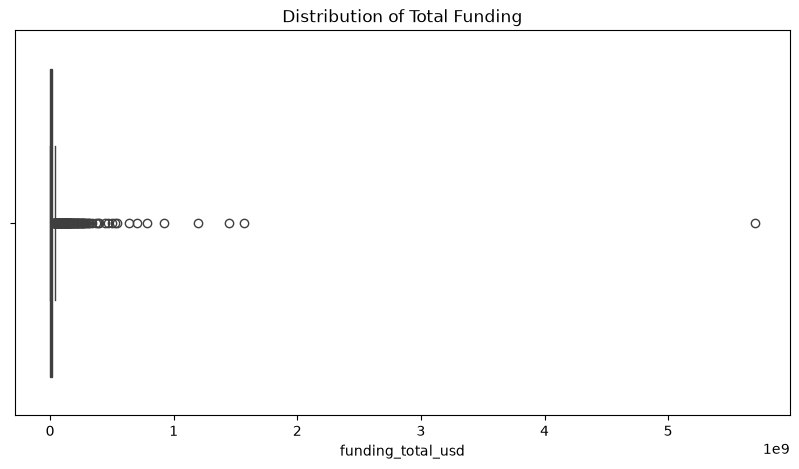

In [30]:
plt.figure(figsize=(10,5))
sns.boxplot(x=dst['funding_total_usd'])
plt.title("Distribution of Total Funding")
plt.show()